# Example 5 — Coherent form factors and nuclear models

This notebook walks through two pieces of nuclear physics that show up in trident calculations on heavy targets:

1. **Coherent nuclear form factor.** The coherent regime carries an explicit $F(Q^2)$ that suppresses contributions at high $Q^2$ (above the inverse nuclear radius). Different parametrisations of $F(Q^2)$ disagree at the few-percent level on heavy nuclei.
2. **Nuclear models for the incoherent regime.** Diffractive (per-nucleon elastic), resonance, and DIS all need a Pauli-blocking prescription on the struck nucleon. neptune ships three models: free-nucleon (no blocking), uniform Fermi gas, and density-folded local Fermi gas.


In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import neptune as nep

## 1) Coherent nuclear form factors

The coherent piece carries an explicit nuclear form factor $F(Q^2)$, normalised so $F(0)=1$. neptune ships two parametrisations:

* `'woods-saxon'` (default): the analytic Woods–Saxon Fourier transform — A-only, identical to the C++ reference. Smooth and parameter-free.
* `'darknews'`: the DarkNews per-nucleus form factor. Where the Fourier–Bessel coefficients have been measured (Nuclear Data Tables; covers most stable isotopes), it uses those directly; otherwise it falls back to a symmetrised Fermi profile keyed by $A$.

You can also pass any callable `f(Q^2)` of your own (e.g. a Helm form factor or a custom parametrisation).

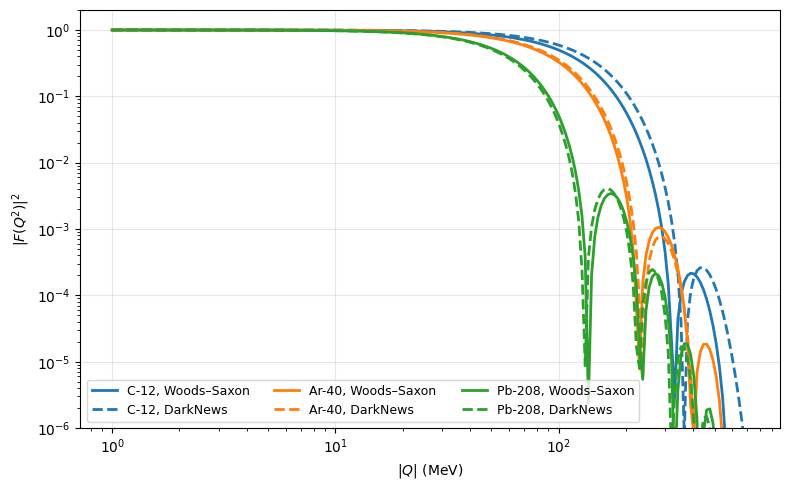

In [2]:
# Compare F(Q^2) for the two parametrisations on three nuclei
Q2_grid = np.geomspace(1e-6, 5e-1, 200)   # GeV^2
Q_grid_MeV = np.sqrt(Q2_grid) * 1e3

fig, ax = plt.subplots(figsize=(8, 5))
for name, Z, A, color in [('C-12', 6, 12, 'C0'), ('Ar-40', 18, 40, 'C1'), ('Pb-208', 82, 208, 'C2')]:
    F_ws = nep.get_form_factor('woods-saxon', Z=Z, A=A)
    F_dn = nep.get_form_factor('darknews',    Z=Z, A=A)
    ax.plot(Q_grid_MeV, F_ws(Q2_grid)**2, color=color, lw=2, label=f'{name}, Woods–Saxon')
    ax.plot(Q_grid_MeV, F_dn(Q2_grid)**2, color=color, lw=2, ls='--', label=f'{name}, DarkNews')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$|Q|$ (MeV)')
ax.set_ylabel(r'$|F(Q^2)|^2$')
ax.set_ylim(1e-6, 2)
ax.legend(ncol=3, fontsize=9, loc='lower left'); ax.grid(alpha=0.3)
plt.tight_layout()

In [3]:
# Coherent dimuon trident xsec at E_nu = 10 GeV for both choices
model_ff = nep.TridentSMModel(nu_flavor='mu', l1_flavor='mu', l2_flavor='mu')
rows = []
for name, Z, A in [('C-12', 6, 12), ('Ar-40', 18, 40), ('Fe-56', 26, 56), ('Pb-208', 82, 208)]:
    out = {'target': name, 'Z': Z, 'A': A}
    for ff in ['woods-saxon', 'darknews']:
        proc = nep.TridentProcess(model_ff, Z=Z, A=A, Enu=10.0,
                                  form_factor=ff, nitn=6, neval=10_000)
        coh, sd = proc.sigma_coherent()
        out[f'sigma_coh ({ff})'] = coh
    out['ratio (DN / WS)'] = out['sigma_coh (darknews)'] / out['sigma_coh (woods-saxon)']
    rows.append(out)
df_ff = pd.DataFrame(rows)
df_ff.style.format({c: '{:.3e}' for c in df_ff.columns if 'sigma' in c}
                    | {'ratio (DN / WS)': '{:.3f}'})

,target,Z,A,sigma_coh (woods-saxon),sigma_coh (darknews),ratio (DN / WS)
0,C-12,6,12,8.793e-43,1.089e-42,1.238
1,Ar-40,18,40,5.261e-42,5.549e-42,1.055
2,Fe-56,26,56,9.560e-42,9.885e-42,1.034
3,Pb-208,82,208,4.889e-41,4.640e-41,0.949


/Users/mhostert/Repos/neptune/src/neptune/nuclear_tools.py:181: RuntimeWarning: overflow encountered in sinh
  den = safe_q**3 * np.sinh(np.pi * safe_q * a) * (r0**2 + np.pi**2 * a**2) * r0
/Users/mhostert/Repos/neptune/src/neptune/nuclear_tools.py:181: RuntimeWarning: overflow encountered in multiply
  den = safe_q**3 * np.sinh(np.pi * safe_q * a) * (r0**2 + np.pi**2 * a**2) * r0


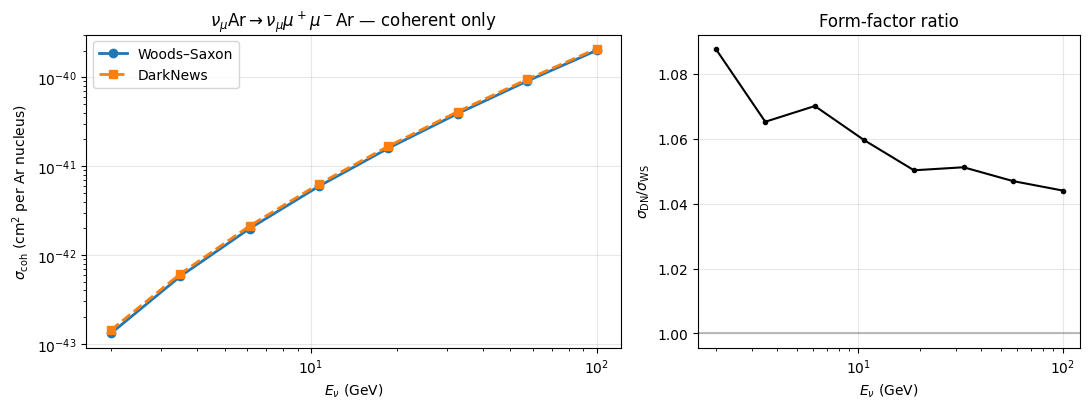

In [4]:
# Energy scan on Argon comparing the two form-factor choices
Enu_scan = np.geomspace(2.0, 100.0, 8)
sig_ws = np.zeros_like(Enu_scan)
sig_dn = np.zeros_like(Enu_scan)
for i, E in enumerate(Enu_scan):
    p_ws = nep.TridentProcess(model_ff, Z=18, A=40, Enu=E,
                              form_factor='woods-saxon', nitn=6, neval=8_000)
    p_dn = nep.TridentProcess(model_ff, Z=18, A=40, Enu=E,
                              form_factor='darknews',    nitn=6, neval=8_000)
    sig_ws[i] = p_ws.sigma_coherent()[0]
    sig_dn[i] = p_dn.sigma_coherent()[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios': [1.4, 1]})
axes[0].plot(Enu_scan, sig_ws, 'o-',  label='Woods–Saxon', lw=2)
axes[0].plot(Enu_scan, sig_dn, 's--', label='DarkNews',    lw=2)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel(r'$E_\nu$ (GeV)')
axes[0].set_ylabel(r'$\sigma_\mathrm{coh}$ (cm$^2$ per Ar nucleus)')
axes[0].set_title(r'$\nu_\mu \mathrm{Ar} \to \nu_\mu \mu^+ \mu^- \mathrm{Ar}$ — coherent only')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(Enu_scan, sig_dn / sig_ws, 'k.-')
axes[1].axhline(1.0, color='gray', alpha=0.5)
axes[1].set_xscale('log')
axes[1].set_xlabel(r'$E_\nu$ (GeV)')
axes[1].set_ylabel(r'$\sigma_\mathrm{DN} / \sigma_\mathrm{WS}$')
axes[1].set_title('Form-factor ratio')
axes[1].grid(alpha=0.3)
plt.tight_layout()

## 2) Nuclear models for the incoherent regime

The diffractive, resonance, and DIS regimes all describe scattering off a *single* bound nucleon. In a nucleus, that bound nucleon (i) is moving with some Fermi momentum and (ii) cannot scatter into a state already occupied by another nucleon — the **Pauli blocking**.

neptune offers three increasingly realistic models, all sharing the interface `nuclear_model.pauli_factor(|q|)`:

| Model | Class | Description |
|---|---|---|
| Free nucleon | `FreeNucleon()` | No nuclear effects: $f_{PB}(\|q\|) \equiv 1$. |
| Uniform Fermi gas | `FermiGas(p_F=...)` | Constant Fermi momentum throughout the nucleus; analytic Smith–Moniz formula. |
| Local Fermi gas | `LocalFermiGas(WoodsSaxonDensity(...))` | Density-dependent $p_F(r) = \hbar c \,(3\pi^2 \rho(r)/2)^{1/3}$ folded over a Woods–Saxon profile. |

Pass any of them as `nuclear_model=...` to `TridentProcess` — applied to the diffractive, DIS, and resonance integrands. The coherent regime is unaffected at LO (the nuclear charge form factor already encodes the nuclear elastic response).

In [5]:
from neptune.nuclear_models import (
    FreeNucleon, FermiGas, LocalFermiGas,
    WoodsSaxonDensity, woods_saxon_density_for, FERMI_MOMENTUM_GEV,
)

ar40_density = woods_saxon_density_for('Ar40')
free_nm  = FreeNucleon()
fg_nm    = FermiGas.for_nucleus('Ar40')      # p_F = 0.251 GeV
lfg_nm   = LocalFermiGas(ar40_density)

print(f'Density:                {ar40_density}')
print(f'  central  ρ₀          = {ar40_density.rho(0):.3f} fm⁻³')
print(f'  central  p_F         = {ar40_density.p_F_isoscalar(0):.3f} GeV')
print(f'  half-density p_F     = {ar40_density.p_F_isoscalar(ar40_density.c):.3f} GeV')
print(f'Models:')
print(f'  {free_nm!r}')
print(f'  {fg_nm!r}')
print(f'  {lfg_nm!r} (effective p_F = {lfg_nm.effective_p_F:.3f} GeV)')

Density:                WoodsSaxonDensity(A=40, Z=18, c=3.53 fm, a=0.542 fm)
  central  ρ₀          = 0.176 fm⁻³
  central  p_F         = 0.271 GeV
  half-density p_F     = 0.216 GeV
Models:
  <FreeNucleon>
  FermiGas(p_F=0.251 GeV)
  LocalFermiGas(WoodsSaxonDensity(A=40, Z=18, c=3.53 fm, a=0.542 fm)) (effective p_F = 0.221 GeV)


### Pauli factor versus three-momentum transfer

The Pauli factor $f_{PB}(|q|)$ is the multiplicative suppression on the per-nucleon cross section from blocking by occupied states in the Fermi sea. It rises from 0 at $|q| \to 0$ to 1 at $|q| \gtrsim 2 p_F$, where the final-state nucleon escapes the Fermi sphere with certainty.

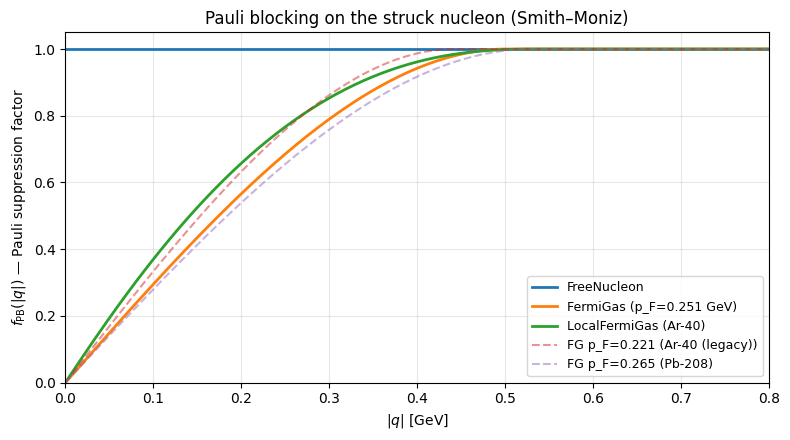

In [6]:
qmag_grid = np.linspace(0.0, 0.8, 400)   # GeV
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(qmag_grid, free_nm.pauli_factor(qmag_grid), lw=2, label='FreeNucleon')
ax.plot(qmag_grid, fg_nm.pauli_factor(qmag_grid),   lw=2, label=f'FermiGas (p_F={fg_nm.p_F:.3f} GeV)')
ax.plot(qmag_grid, lfg_nm.pauli_factor(qmag_grid),  lw=2, label='LocalFermiGas (Ar-40)')
for pF, name in [(0.221, 'Ar-40 (legacy)'), (0.265, 'Pb-208')]:
    ax.plot(qmag_grid, FermiGas(p_F=pF).pauli_factor(qmag_grid), ls='--', alpha=0.5,
             label=f'FG p_F={pF:.3f} ({name})')
ax.set_xlabel(r'$|q|$ [GeV]')
ax.set_ylabel(r'$f_\mathrm{PB}(|q|)$ — Pauli suppression factor')
ax.set_title('Pauli blocking on the struck nucleon (Smith–Moniz)')
ax.grid(alpha=0.3); ax.legend(loc='lower right', fontsize=9)
ax.set_xlim(0, 0.8); ax.set_ylim(0, 1.05)
plt.tight_layout()

### Effect on σ_diffractive at fixed Eν

Diffractive trident is dominated by small-$Q^2$ (small $|q|$) photons, so it is the regime most sensitive to Pauli blocking. On argon at 10 GeV, free nucleons give a rate about 30% above the Fermi gas. The LFG agrees with the FG at $p_F = 0.221$ GeV to 2%, and lies about 8% above the FG at the Ar-40 fit value $p_F = 0.251$ GeV.

In [7]:
model_diff = nep.TridentSMModel(nu_flavor='mu', l1_flavor='mu', l2_flavor='mu')
Enu_dif = 10.0
rows = []
for nm, label in [(FreeNucleon(),                 'FreeNucleon'),
                  (FermiGas(p_F=0.221),            'FG p_F=0.221'),
                  (FermiGas.for_nucleus('Ar40'),   'FG p_F=0.251 (Ar-40 fit)'),
                  (LocalFermiGas(ar40_density),    'LFG (Ar-40)')]:
    proc = nep.TridentProcess(model_diff, Z=18, A=40, Enu=Enu_dif,
                               nuclear_model=nm, nitn=6, neval=8_000)
    s, sd = proc.sigma_diffractive()
    rows.append(dict(model=label, sigma_dif=s, sdev=sd))
df = pd.DataFrame(rows)
ref = df.iloc[0]['sigma_dif']
df['ratio_to_free'] = df['sigma_dif'] / ref
print(f'Ar-40, E_nu = {Enu_dif:g} GeV')
display(df.style.format({'sigma_dif': '{:.3e}', 'sdev': '{:.2e}', 'ratio_to_free': '{:.3f}'}))

Ar-40, E_nu = 10 GeV


,model,sigma_dif,sdev,ratio_to_free
0,FreeNucleon,3.076e-42,8.99e-45,1.000
1,FG p_F=0.221,2.309e-42,6.72e-45,0.751
2,FG p_F=0.251 (Ar-40 fit),2.177e-42,6.29e-45,0.708
3,LFG (Ar-40),2.343e-42,6.81e-45,0.761


### Energy dependence of the nuclear-model effect

The Pauli suppression is concentrated at low $|q|$, which corresponds to low $E_\nu$ (where the leptons are produced softly). At high $E_\nu$ the kinematics push $|q|$ above $2 p_F$ and all three models converge.

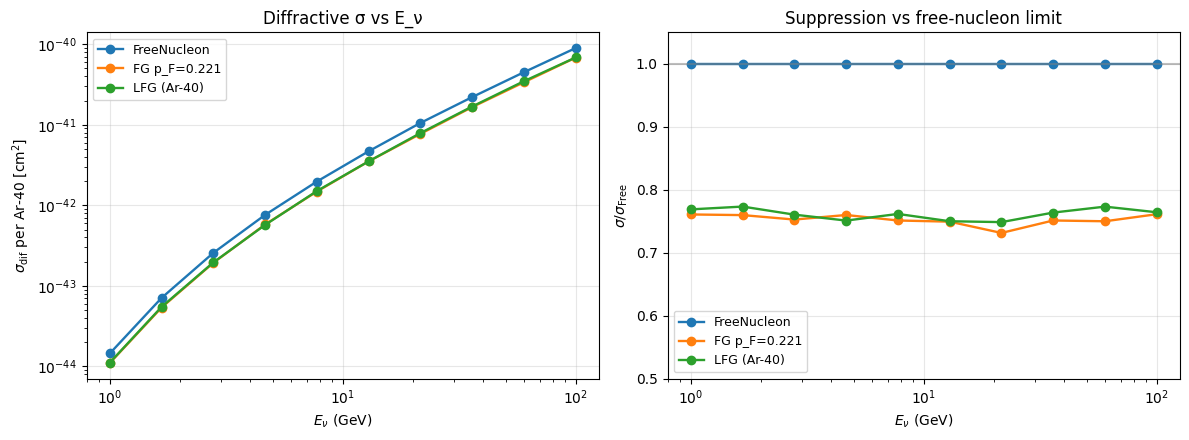

In [8]:
Enu_scan = np.geomspace(1.0, 100.0, 10)
sigma_models = {
    'FreeNucleon': np.zeros_like(Enu_scan),
    'FG p_F=0.221': np.zeros_like(Enu_scan),
    'LFG (Ar-40)':  np.zeros_like(Enu_scan),
}
model_to_nm = {
    'FreeNucleon': FreeNucleon(),
    'FG p_F=0.221': FermiGas(p_F=0.221),
    'LFG (Ar-40)':  LocalFermiGas(ar40_density),
}
for i, E in enumerate(Enu_scan):
    for label, nm in model_to_nm.items():
        proc = nep.TridentProcess(model_diff, Z=18, A=40, Enu=float(E),
                                   nuclear_model=nm, nitn=4, neval=4_000)
        sigma_models[label][i] = proc.sigma_diffractive()[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for label, sigma in sigma_models.items():
    axes[0].plot(Enu_scan, sigma, 'o-', label=label, lw=1.7)
    axes[1].plot(Enu_scan, sigma / sigma_models['FreeNucleon'],
                  'o-', label=label, lw=1.7)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel(r'$E_\nu$ (GeV)')
axes[0].set_ylabel(r'$\sigma_\mathrm{dif}$ per Ar-40 [cm$^2$]')
axes[0].set_title('Diffractive σ vs E_ν')
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)
axes[1].set_xscale('log')
axes[1].set_xlabel(r'$E_\nu$ (GeV)')
axes[1].set_ylabel(r'$\sigma / \sigma_\mathrm{Free}$')
axes[1].set_title('Suppression vs free-nucleon limit')
axes[1].axhline(1.0, color='gray', alpha=0.5)
axes[1].set_ylim(0.5, 1.05); axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)
plt.tight_layout()

### Effect on σ_resonance

The Δ-resonance regime samples slightly larger $|q|$ than diffractive (the BW peak sits at $W \approx 1.232$ GeV, requiring more energy transfer to the nucleon), so the Pauli suppression is somewhat milder.

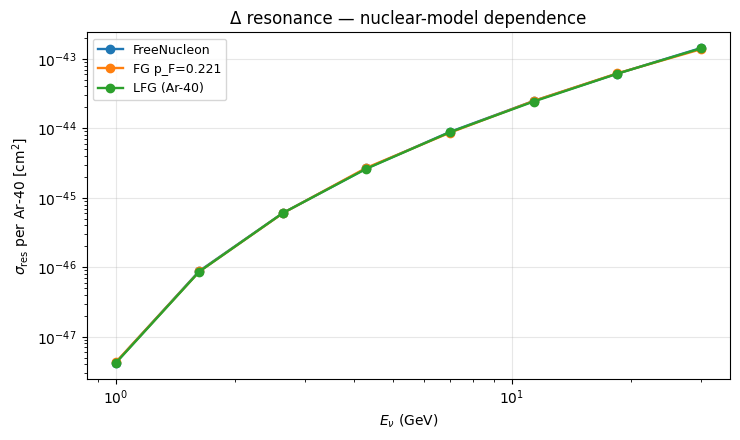

In [9]:
Enu_res_scan = np.geomspace(1.0, 30.0, 8)
rows = []
for E in Enu_res_scan:
    row = {'Enu': float(E)}
    for label, nm in model_to_nm.items():
        proc = nep.TridentProcess(model_diff, Z=18, A=40, Enu=float(E),
                                   nuclear_model=nm, nitn=4, neval=4_000)
        row[label] = proc.sigma_resonance()[0]
    rows.append(row)
df_res = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for label in model_to_nm:
    ax.plot(df_res['Enu'], df_res[label], 'o-', label=label, lw=1.7)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$E_\nu$ (GeV)')
ax.set_ylabel(r'$\sigma_\mathrm{res}$ per Ar-40 [cm$^2$]')
ax.set_title(r'Δ resonance — nuclear-model dependence')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()

### Plug-in convenience: standard nuclei

Standard Woods–Saxon parameters and constant-$p_F$ values are tabulated for common targets (de Vries et al. 1987 + Smith–Moniz fits). Look-up by symbol via `woods_saxon_density_for(symbol)` and `FermiGas.for_nucleus(symbol)`.

In [10]:
from neptune.nuclear_models import WOODS_SAXON_PARAMS
tbl = []
for sym, params in WOODS_SAXON_PARAMS.items():
    d = woods_saxon_density_for(sym)
    tbl.append(dict(
        symbol=sym, **params,
        rho_central=d.rho(0),
        pF_central=d.p_F_isoscalar(0),
        pF_FG=FERMI_MOMENTUM_GEV[sym],
    ))
pd.DataFrame(tbl).style.format({
    'rho_central': '{:.4f} fm⁻³', 'pF_central': '{:.3f} GeV', 'pF_FG': '{:.3f} GeV',
    'c': '{:.3f} fm', 'a': '{:.3f} fm',
})

,symbol,A,Z,c,a,rho_central,pF_central,pF_FG
0,C12,12,6,2.355 fm,0.522 fm,0.1460 fm⁻³,0.255 GeV,0.221 GeV
1,O16,16,8,2.608 fm,0.513 fm,0.1548 fm⁻³,0.260 GeV,0.225 GeV
2,Ar40,40,18,3.530 fm,0.542 fm,0.1759 fm⁻³,0.271 GeV,0.251 GeV
3,Fe56,56,26,4.106 fm,0.519 fm,0.1668 fm⁻³,0.267 GeV,0.255 GeV
4,Pb208,208,82,6.620 fm,0.546 fm,0.1604 fm⁻³,0.263 GeV,0.265 GeV


## 3) Atomic Coulomb screening of the nuclear charge

Bound atomic electrons screen the bare nuclear charge at very small $Q^2$ — the photon below the Thomas–Fermi cutoff $Q^2 \lesssim 1/a_{\rm TF}^2$ couples to a *neutral atom* rather than to the nucleus. This is most consequential for **light di-lepton final states** ($e^+e^-$, light dark matter), where the kinematic $Q^2_{\min}$ from the lepton mass sits near the Thomas–Fermi scale and the screening function reshapes the photon flux.

neptune ships two parametrisations of the multiplicative screening factor $G_{\rm at}(Q^2)$:

| `atomic_screening=` | Function | Comment |
|---|---|---|
| `'tsai'` (or `'thomas-fermi'`) | $G(Q^2) = x/(1+x), \; x = Q^2 a_{\rm TF}^2$ | Tsai, *Rev. Mod. Phys.* 46 (1974). One-line analytic. |
| `'moliere'` | 3-exponential Moliere screening | Universal coefficients; close stand-in for the Z-dependent Salvat–Martínez–Mayol–Parellada parameterisation used by GEANT4. |
| `'salvat'` | Salvat–MMP, *Phys. Rev. A* 36 (1987) | Requires the per-Z $(\alpha_i, \lambda_i)$ table — drop into `nuclear_tools._SALVAT_PARAMS` to enable. |

Both replace the bare nuclear form factor by $F_{\rm nucl}(Q^2) \cdot G_{\rm at}(Q^2)$ inside the coherent integrand. The diffractive, resonance, and DIS regimes are unaffected — there the photon couples to a *nucleon*, not to the atom.

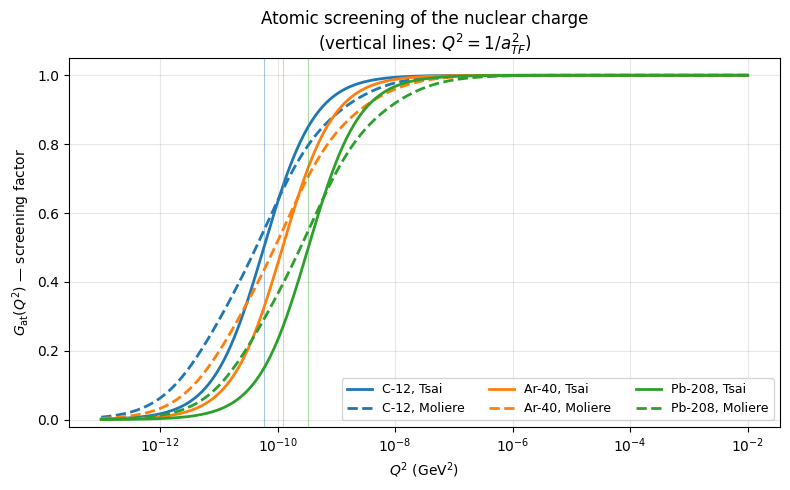

In [11]:
from neptune.nuclear_tools import (
    atomic_screening_factor, thomas_fermi_length,
)

Q2_grid = np.geomspace(1e-13, 1e-2, 400)
fig, ax = plt.subplots(figsize=(8, 5))
for Z, name, color in [(6,'C-12','C0'), (18,'Ar-40','C1'), (82,'Pb-208','C2')]:
    g_tsai = atomic_screening_factor(Q2_grid, Z, 'tsai')
    g_mol  = atomic_screening_factor(Q2_grid, Z, 'moliere')
    a_tf   = thomas_fermi_length(Z)
    Q2_TF  = 1.0 / a_tf**2
    ax.plot(Q2_grid, g_tsai, color=color, lw=2, label=f'{name}, Tsai')
    ax.plot(Q2_grid, g_mol,  color=color, lw=2, ls='--', label=f'{name}, Moliere')
    ax.axvline(Q2_TF, color=color, lw=0.8, alpha=0.4)
ax.set_xscale('log')
ax.set_xlabel(r'$Q^2$ (GeV$^2$)')
ax.set_ylabel(r'$G_\mathrm{at}(Q^2)$ — screening factor')
ax.set_title('Atomic screening of the nuclear charge\n(vertical lines: $Q^2 = 1/a_{TF}^2$)')
ax.legend(ncol=3, fontsize=9, loc='lower right')
ax.grid(alpha=0.3); ax.set_ylim(-0.02, 1.05)
plt.tight_layout()

### Effect on the coherent $e^+e^-$ cross section

$e^+e^-$ trident is sensitive to small $Q^2$ photons; the kinematic $Q^2_{\min}$ for $e^+e^-$ on Argon at GeV-scale $E_\nu$ is comparable to $1/a_{\rm TF}^2$, so screening reshuffles the integration support visibly.

In [12]:
model_ee = nep.TridentSMModel(nu_flavor='mu', l1_flavor='e', l2_flavor='e')
Z, A = 18, 40
rows = []
for Enu in (0.5, 1.0, 2.0, 5.0):
    out = {'Enu (GeV)': Enu}
    for sc in (None, 'tsai', 'moliere'):
        proc = nep.TridentProcess(model_ee, Z=Z, A=A, Enu=Enu,
                                   atomic_screening=sc,
                                   nitn=6, neval=8_000)
        s, sd = proc.sigma_coherent()
        out[f'σ ({sc or "unscreened"})'] = s
    out['Tsai/unscreened'] = out['σ (tsai)'] / out['σ (unscreened)']
    out['Moliere/unscreened'] = out['σ (moliere)'] / out['σ (unscreened)']
    rows.append(out)
df_ee_sc = pd.DataFrame(rows)
print(f'ν_μ + Ar-40 → ν_μ e⁻ e⁺ + Ar-40, coherent regime')
display(df_ee_sc.style.format(
    {c: '{:.3e}' for c in df_ee_sc.columns if 'σ' in c}
    | {'Tsai/unscreened': '{:.3f}', 'Moliere/unscreened': '{:.3f}'}
))

ν_μ + Ar-40 → ν_μ e⁻ e⁺ + Ar-40, coherent regime


,Enu (GeV),σ (unscreened),σ (tsai),σ (moliere),Tsai/unscreened,Moliere/unscreened
0,0.500000,1.337e-43,1.342e-43,1.335e-43,1.004,0.999
1,1.000000,3.796e-43,3.778e-43,3.796e-43,0.995,1.000
2,2.000000,1.012e-42,9.823e-43,9.941e-43,0.970,0.982
3,5.000000,3.305e-42,3.367e-42,3.309e-42,1.019,1.001


### Differential dσ/d|Q| with and without screening

Where the screening reshapes the cross section is most visible in the photon-virtuality differential distribution. We sample the coherent integrand on a Vegas-trained map and bin in $|Q| = \sqrt{Q^2}$, comparing the unscreened and Tsai-screened cases at $E_\nu = 1$ GeV.

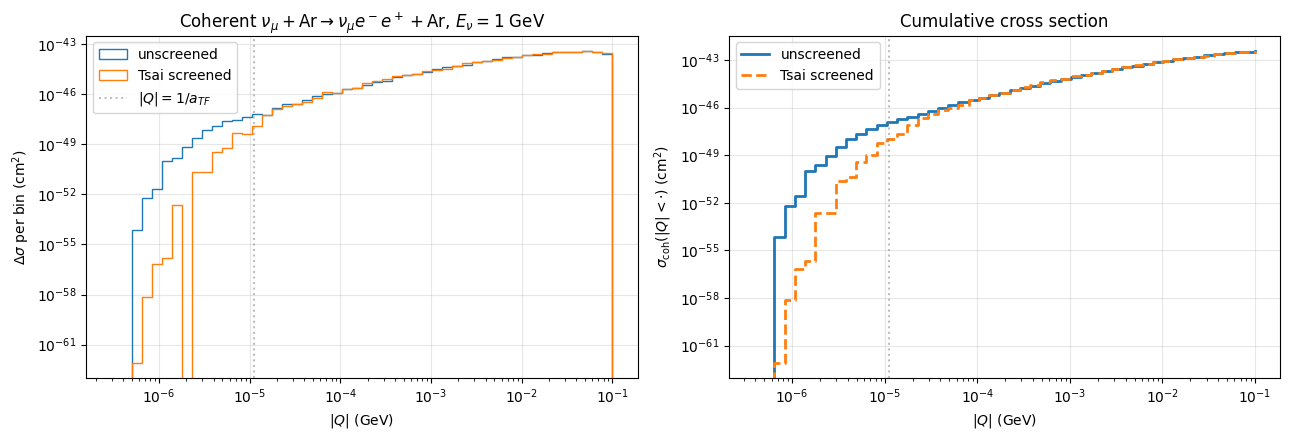

In [13]:
from neptune.MC import TridentGenerator

Z, A, Enu = 18, 40, 1.0
qbin_edges = np.geomspace(3e-7, 1e-1, 51)   # |Q| in GeV
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for sc, color, ls in [(None, 'C0', '-'), ('tsai', 'C1', '--')]:
    gen = TridentGenerator(
        model_ee, Z=Z, A=A, Enu=Enu,
        atomic_screening=sc,
        n_events=20_000, nitn=6, neval=20_000, seed=1,
    )
    ev = gen.generate(verbose=False)
    coh_mask = ev['mode'] == 'coherent'
    Q   = np.sqrt(np.maximum(ev['x1'][coh_mask], 0.0))
    w   = ev['weight'][coh_mask]
    label = 'unscreened' if sc is None else 'Tsai screened'
    axes[0].hist(Q, bins=qbin_edges, weights=w,
                  histtype='step', label=label, lw=2, color=color, ls=ls)
    # cumulative integral \int^{|Q|} dQ' (dσ/dQ')
    counts, _ = np.histogram(Q, bins=qbin_edges, weights=w)
    cum = np.cumsum(counts)
    axes[1].step(qbin_edges[1:], cum, where='post',
                  label=label, lw=2, color=color, ls=ls)

axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel(r'$|Q|$ (GeV)')
axes[0].set_ylabel(r'$\Delta\sigma$ per bin (cm$^2$)')
axes[0].set_title(rf'Coherent $\nu_\mu + \mathrm{{Ar}} \to \nu_\mu e^- e^+ + \mathrm{{Ar}}$, $E_\nu = {Enu:g}$ GeV')
axes[0].axvline(np.sqrt(1/thomas_fermi_length(Z)**2), color='gray', alpha=0.5,
                  ls=':', label=r'$|Q| = 1/a_{TF}$')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel(r'$|Q|$ (GeV)')
axes[1].set_ylabel(r'$\sigma_\mathrm{coh}(|Q|<\cdot)$ (cm$^2$)')
axes[1].set_title('Cumulative cross section')
axes[1].axvline(np.sqrt(1/thomas_fermi_length(Z)**2), color='gray', alpha=0.5, ls=':')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()

/Users/mhostert/Repos/neptune/src/neptune/nuclear_tools.py:181: RuntimeWarning: overflow encountered in sinh
  den = safe_q**3 * np.sinh(np.pi * safe_q * a) * (r0**2 + np.pi**2 * a**2) * r0
/Users/mhostert/Repos/neptune/src/neptune/nuclear_tools.py:181: RuntimeWarning: overflow encountered in multiply
  den = safe_q**3 * np.sinh(np.pi * safe_q * a) * (r0**2 + np.pi**2 * a**2) * r0


/var/folders/dl/ccbsfs591r1fhgcws28m8xy40000gn/T/ipykernel_68172/347881184.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


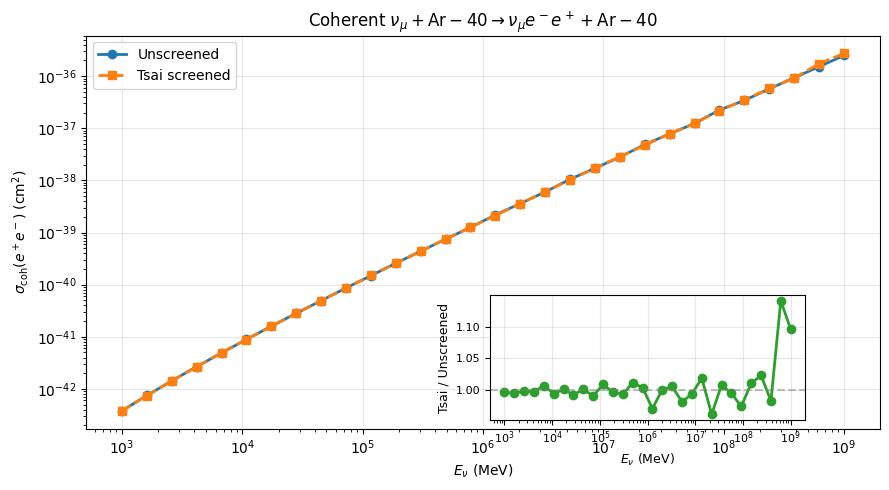

In [14]:
# Total coherent cross section for e+e- across energy range, with and without screening
Enu_range = np.geomspace(1, 1e6, 30)  # GeV
sigma_unscreened = np.zeros_like(Enu_range)
sigma_tsai = np.zeros_like(Enu_range)

for i, E in enumerate(Enu_range):
    proc_unsc = nep.TridentProcess(model_ee, Z=18, A=40, Enu=E,
                                    atomic_screening=None,
                                    nitn=5, neval=100_000)
    proc_tsai = nep.TridentProcess(model_ee, Z=18, A=40, Enu=E,
                                    atomic_screening='tsai',
                                    nitn=5, neval=100_000)
    sigma_unscreened[i] = proc_unsc.sigma_coherent()[0]
    sigma_tsai[i] = proc_tsai.sigma_coherent()[0]

fig, ax = plt.subplots(figsize=(9, 5))
ax.loglog(Enu_range * 1e3, sigma_unscreened, 'o-', label='Unscreened', lw=2)
ax.loglog(Enu_range * 1e3, sigma_tsai, 's--', label='Tsai screened', lw=2)
ax.set_xlabel(r'$E_\nu$ (MeV)')
ax.set_ylabel(r'$\sigma_\mathrm{coh}(e^+e^-)$ (cm$^2$)')
ax.set_title(r'Coherent $\nu_\mu + \mathrm{Ar-40} \to \nu_\mu e^- e^+ + \mathrm{Ar-40}$')
ax.legend(); ax.grid(alpha=0.3)
axes_ratio = fig.add_axes([0.55, 0.15, 0.35, 0.25])
axes_ratio.semilogx(Enu_range * 1e3, sigma_tsai / sigma_unscreened, 'o-', color='C2', lw=2)
axes_ratio.axhline(1.0, color='gray', alpha=0.5, ls='--')
axes_ratio.set_xlabel(r'$E_\nu$ (MeV)', fontsize=9)
axes_ratio.set_ylabel(r'Tsai / Unscreened', fontsize=9)
axes_ratio.tick_params(labelsize=8)
axes_ratio.grid(alpha=0.3)
plt.tight_layout()


### Z dependence of the screening effect

Heavier nuclei have shorter $a_{\rm TF}$, so the Thomas–Fermi cutoff sits at higher $Q^2$ and the screening cuts more deeply into the photon flux.

In [15]:
Enu = 2.0
rows = []
for Zt, At, name in [(6, 12, 'C-12'), (18, 40, 'Ar-40'), (26, 56, 'Fe-56'), (82, 208, 'Pb-208')]:
    out = {'target': name, 'Z': Zt, 'A': At}
    for sc in (None, 'tsai'):
        proc = nep.TridentProcess(model_ee, Z=Zt, A=At, Enu=Enu,
                                   atomic_screening=sc,
                                   nitn=6, neval=8_000)
        out[f'σ ({sc or "unscr."})'] = proc.sigma_coherent()[0]
    out['Tsai / unscreened'] = out['σ (tsai)'] / out['σ (unscr.)']
    rows.append(out)
df_Z_sc = pd.DataFrame(rows)
print(f'Coherent ν_μ → ν_μ e⁻e⁺ at E_ν = {Enu} GeV')
display(df_Z_sc.style.format(
    {c: '{:.3e}' for c in df_Z_sc.columns if 'σ' in c}
    | {'Tsai / unscreened': '{:.3f}'}
))

Coherent ν_μ → ν_μ e⁻e⁺ at E_ν = 2.0 GeV


,target,Z,A,σ (unscr.),σ (tsai),Tsai / unscreened
0,C-12,6,12,1.301e-43,1.288e-43,0.990
1,Ar-40,18,40,1.005e-42,1.008e-42,1.003
2,Fe-56,26,56,2.006e-42,1.974e-42,0.984
3,Pb-208,82,208,1.565e-41,1.542e-41,0.986


### Why this matters less at neptune's default cuts

The neptune phase-space mapping already integrates $Q^2$ down to its kinematic lower limit
$Q^2_{\min} = (m_1 + m_2)^4 / Q^2_{\max} / (1 + 2 E_\nu / M_N)$,
which for $e^+e^-$ on Argon at GeV-scale $E_\nu$ sits near $10^{-9}$ GeV² — already comparable to $1/a_{\rm TF}^2 \approx 1.2 \times 10^{-10}$ GeV². So the unscreened neptune integral is *already* bounded near the Thomas–Fermi scale, and the multiplicative screening only reshapes the integrand by $\mathcal{O}(\text{few \%})$ rather than by a factor of several. Calculations that use a hard cutoff at the lepton mass (e.g. $Q^2_{\min} = 4 m_e^2$ ≈ $10^{-6}$ GeV²) will see a much larger relative effect from turning on screening, because the cutoff scale shifts from $4 m_e^2$ down to $1/a_{\rm TF}^2$ — a factor of $\sim 10^4$ in $Q^2$.

For heavy lepton final states ($\mu^+\mu^-$, $\tau^+\tau^-$) screening has essentially no effect, since $Q^2_{\min}$ is set by the lepton mass and is many orders of magnitude above $1/a_{\rm TF}^2$. We can verify:

In [16]:
model_mu = nep.TridentSMModel(nu_flavor='mu', l1_flavor='mu', l2_flavor='mu')
rows = []
for Enu in (2.0, 10.0, 50.0):
    out = {'Enu (GeV)': Enu}
    for sc in (None, 'tsai'):
        proc = nep.TridentProcess(model_mu, Z=18, A=40, Enu=Enu,
                                   atomic_screening=sc,
                                   nitn=4, neval=4_000)
        out[f'σ ({sc or "unscr."})'] = proc.sigma_coherent()[0]
    out['Tsai / unscreened'] = out['σ (tsai)'] / out['σ (unscr.)']
    rows.append(out)
df_mu_sc = pd.DataFrame(rows)
print('Coherent ν_μ → ν_μ μ⁻μ⁺ on Ar-40 — no screening sensitivity expected')
display(df_mu_sc.style.format(
    {c: '{:.3e}' for c in df_mu_sc.columns if 'σ' in c}
    | {'Tsai / unscreened': '{:.3f}'}
))

Coherent ν_μ → ν_μ μ⁻μ⁺ on Ar-40 — no screening sensitivity expected


,Enu (GeV),σ (unscr.),σ (tsai),Tsai / unscreened
0,2.000000,1.322e-43,1.300e-43,0.983
1,10.000000,5.257e-42,5.277e-42,1.004
2,50.000000,7.412e-41,7.438e-41,1.003


## 4) Trident on atomic electrons

In addition to the four nucleon-target regimes, the photon can also be radiated coherently off an *atomic electron* — neutrino-trident production on the bound electrons of the target atom. neptune treats this in the impulse approximation:

* The bound electron is approximated as a free fermion of mass $m_e$.
* The per-atom rate is $Z \cdot \sigma_e^{\rm per\,electron}$ (incoherent sum over the $Z$ atomic electrons).
* No Pauli blocking is applied (atomic electrons are not in a degenerate Fermi sea).
* Atomic binding (~ keV–MeV) is neglected — small for trident at GeV-scale $E_\nu$.

The flux functions $h_T^{\rm ele}$, $h_L^{\rm ele}$ are point-like analogues of the nucleon ones: no form factor, target mass set to $m_e$. Exposed via:

```python
proc.sigma_electron()              # per atom (= Z × per-electron)
proc.sigma_electron_per_e()        # per single free electron
proc.sigma_total(include_electron=True)   # adds 'electron' to the breakdown
```

Internally, this is the new `regime='electron'` of `differential_cross_section_tl` and the `ElectronTridentIntegrand` class.

### Cross-section ordering: e+e- final state on Argon

For the dominant light-pair channel ($e^+e^-$), the trident-on-electron rate is much smaller than the coherent-on-nucleus rate because of the missing $Z^2$ enhancement on the electron side.

In [17]:
model_eee = nep.TridentSMModel(nu_flavor='mu', l1_flavor='e', l2_flavor='e')
Z, A = 18, 40
rows = []
for Enu in (0.5, 1.0, 2.0, 5.0):
    proc = nep.TridentProcess(
        model_eee, Z=Z, A=A, Enu=Enu,
        nitn=6, neval=6_000,
    )
    coh, _   = proc.sigma_coherent()
    dif, _   = proc.sigma_diffractive()
    ele, _   = proc.sigma_electron()
    ele_pe, _ = proc.sigma_electron_per_e()
    rows.append(dict(
        Enu_GeV=Enu,
        sigma_coh=coh,
        sigma_dif=dif,
        sigma_ele_per_e=ele_pe,
        sigma_ele=ele,
        ele_over_coh=ele/coh,
    ))
df_ele = pd.DataFrame(rows)
print(f'ν_μ + Ar-40 → ν_μ e⁻ e⁺ + (Ar-40 or e⁻ recoil)')
display(df_ele.style.format({
    'sigma_coh': '{:.3e}', 'sigma_dif': '{:.3e}',
    'sigma_ele_per_e': '{:.3e}', 'sigma_ele': '{:.3e}',
    'ele_over_coh': '{:.2e}'
}))

ν_μ + Ar-40 → ν_μ e⁻ e⁺ + (Ar-40 or e⁻ recoil)


,Enu_GeV,sigma_coh,sigma_dif,sigma_ele_per_e,sigma_ele,ele_over_coh
0,0.500000,1.343e-43,2.554e-45,1.149e-47,2.040e-46,1.52e-03
1,1.000000,3.874e-43,1.249e-44,2.978e-47,5.403e-46,1.39e-03
2,2.000000,1.015e-42,5.056e-44,7.568e-47,1.354e-45,1.33e-03
3,5.000000,3.377e-42,2.498e-43,2.539e-46,4.539e-45,1.34e-03


### Energy dependence — electron channel rises faster

The trident-on-electron cross section grows roughly linearly with $E_\nu$ (CM energy ≈ $\sqrt{2 m_e E_\nu}$ — the kinematic phase space opens fast); the coherent regime saturates when $E_\nu$ exceeds the inverse nuclear radius.

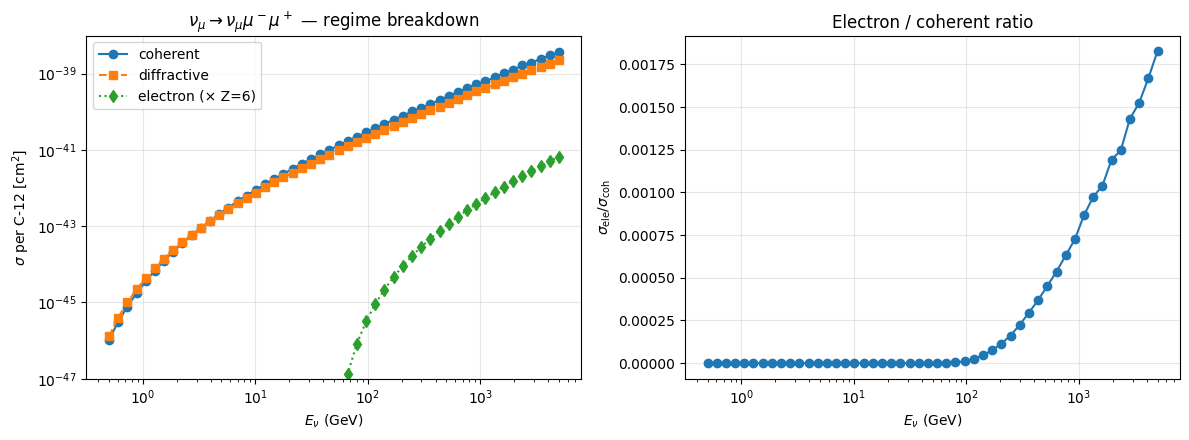

In [18]:
model_mmm = nep.TridentSMModel(nu_flavor='mu', l1_flavor='mu', l2_flavor='mu')
Enu_grid = np.geomspace(0.5, 5e3, 50)
scan_coh = np.zeros_like(Enu_grid)
scan_ele = np.zeros_like(Enu_grid)
scan_dif = np.zeros_like(Enu_grid)
for i, E in enumerate(Enu_grid):
    proc = nep.TridentProcess(model_mmm, Z=6, A=12, Enu=float(E),
                               nitn=4, neval=10_000)
    scan_coh[i] = proc.sigma_coherent()[0]
    scan_dif[i] = proc.sigma_diffractive()[0]
    scan_ele[i] = proc.sigma_electron()[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(Enu_grid, scan_coh, 'o-',  label='coherent')
axes[0].plot(Enu_grid, scan_dif, 's--', label='diffractive')
axes[0].plot(Enu_grid, scan_ele, 'd:',  label='electron (× Z=6)')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel(r'$E_\nu$ (GeV)')
axes[0].set_ylabel(r'$\sigma$ per C-12 [cm$^2$]')
axes[0].set_title(r'$\nu_\mu \to \nu_\mu \mu^- \mu^+$ — regime breakdown')
axes[0].grid(alpha=0.3); axes[0].legend()
axes[0].set_ylim(1e-47, 1e-38)

axes[1].plot(Enu_grid, scan_ele / scan_coh, 'o-')
axes[1].set_xscale('log')
axes[1].set_xlabel(r'$E_\nu$ (GeV)')
axes[1].set_ylabel(r'$\sigma_\mathrm{ele} / \sigma_\mathrm{coh}$')
axes[1].set_title('Electron / coherent ratio')
axes[1].grid(alpha=0.3)
plt.tight_layout()

### Heavy lepton final state: μ⁺μ⁻ on electron is kinematically suppressed

Producing a $\mu^+\mu^-$ pair on a stationary electron has a large lab threshold $E_\nu^{\rm thr} \approx m_\mu^2/m_e \approx 22$ GeV — below this the electron channel is identically zero. Compare with the nucleon-target case where the threshold is essentially $2 m_\mu / 2 \sim 0.21$ GeV.

In [19]:
from neptune.phase_space import trident_threshold
from neptune import const

E_thr_e  = trident_threshold(0.1057, 0.1057, const.m_e)
E_thr_N  = trident_threshold(0.1057, 0.1057, const.m_proton)
print(f'ν + e  → ν + e μ⁻μ⁺  threshold:  E_ν > {E_thr_e:6.2f} GeV')
print(f'ν + N  → ν + N μ⁻μ⁺  threshold:  E_ν > {E_thr_N:6.4f} GeV')

model_mu = nep.TridentSMModel(nu_flavor='mu', l1_flavor='mu', l2_flavor='mu')
rows = []
for Enu in (10.0, 30.0, 100.0):
    proc = nep.TridentProcess(model_mu, Z=18, A=40, Enu=Enu, nitn=4, neval=3_000)
    rows.append(dict(
        Enu=Enu,
        sigma_coh=proc.sigma_coherent()[0],
        sigma_ele_per_atom=proc.sigma_electron()[0],
    ))
df_mu = pd.DataFrame(rows)
df_mu['ele/coh'] = df_mu['sigma_ele_per_atom'] / df_mu['sigma_coh']
print('\nν_μ + Ar → ν_μ μ⁻μ⁺ + (Ar or e⁻):')
display(df_mu.style.format({'sigma_coh': '{:.3e}',
                            'sigma_ele_per_atom': '{:.3e}',
                            'ele/coh': '{:.2e}'}))

ν + e  → ν + e μ⁻μ⁺  threshold:  E_ν >  43.94 GeV
ν + N  → ν + N μ⁻μ⁺  threshold:  E_ν > 0.2352 GeV



ν_μ + Ar → ν_μ μ⁻μ⁺ + (Ar or e⁻):


,Enu,sigma_coh,sigma_ele_per_atom,ele/coh
0,10.000000,5.241e-42,0.000e+00,0.00e+00
1,30.000000,3.489e-41,0.000e+00,0.00e+00
2,100.000000,2.040e-40,1.190e-45,5.83e-06


### Mixed-flavor trident — electron channel has a special role

For *mixed-flavor* finals like $\nu_\mu \to \nu_e\,e^-\mu^+$ (or $\nu_\mu \to \nu_\mu\,e^+\mu^-$ via NC) on an *electron* target, the electron is itself one of the leptons in the final state — different topology, but the same `regime='electron'` integrand applies, and `sigma_electron()` works for any choice of $\ell_1, \ell_2$. (Below threshold the integrand returns identically 0.)

## Where to go next

* For event generation that uses a chosen nuclear model, pass `nuclear_model=...` to `TridentGenerator` (it has the same interface).
* The constant-$p_F$ Fermi-gas was the legacy default for the diffractive integrand (`p_F = 0.221` GeV); we kept that as the backward-compatible fallback, so existing scripts keep their numerical behaviour unchanged.
* The LFG `effective_p_F` matches the legacy 0.221 GeV value for Argon, by construction — so on Ar-40 the two prescriptions agree to a few percent.
* For higher-precision treatments (full Fermi-motion smearing, in-medium Δ width) the framework is in place: `WoodsSaxonDensity` already exposes `rho_p`, `rho_n`, and `p_F_isoscalar`, ready to be folded into a more elaborate `NuclearModel` subclass.